Bengaluru House Price — Exploratory Data Analysis
Student Name: Murari Desai

Project Type: AI/ML Minor Project — EDA

Dataset: Bengaluru House Data

Dataset Source: Paste your Kaggle dataset link here.

Project Objective
The objective of this project is to explore and clean Bengaluru house-price data, understand the distribution of property prices, analyze relationships between property features, and identify useful insights for future machine learning applications.

In [ ]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

sns.set_theme(style='whitegrid')

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Bengaluru_House_Data (1).csv to Bengaluru_House_Data (1) (4).csv


In [ ]:
import pandas as pd

filename = next(iter(uploaded))
df_clean = pd.read_csv(filename)

print(df_clean.shape)
df_clean.head()

(13320, 9)


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
import os

print(os.listdir('/content'))

['.config', 'drive', 'Bengaluru_House_Data (1).csv', 'Bengaluru_House_Data (1) (4).csv', 'Bengaluru_House_Data (1) (2).csv', 'Bengaluru_House_Data (1) (3).csv', 'Bengaluru_House_Data (1) (1).csv', 'sample_data']


In [ ]:
df_clean.duplicated().sum()

np.int64(529)

In [ ]:
df_clean.describe()

,bath,balcony,price
count,13247.000000,12711.000000,13320.000000
mean,2.692610,1.584376,112.565627
std,1.341458,0.817263,148.971674
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,72.000000
75%,3.000000,2.000000,120.000000
max,40.000000,3.000000,3600.000000


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [ ]:
df_clean.isnull().sum()

,0
area_type,0
availability,0
location,1
size,16
society,5502
total_sqft,0
bath,73
balcony,609
price,0


In [ ]:
df_clean.duplicated().sum()

np.int64(529)

In [ ]:
df_clean.drop_duplicates(inplace=True)

In [ ]:
df_clean.duplicated().sum()

np.int64(0)

In [ ]:
df_clean["size"] = df_clean["size"].fillna(df_clean["size"].mode()[0])

In [ ]:
df_clean.isnull().sum()

,0
area_type,0
availability,0
location,1
size,0
society,5328
total_sqft,0
bath,73
balcony,605
price,0


In [ ]:

df_clean["bath"] = df_clean["bath"].fillna(df_clean["bath"].median())

df_clean["balcony"] = df_clean["balcony"].fillna(df_clean["balcony"].median())


In [ ]:
df_clean["location"] = df_clean["location"].fillna(df_clean["location"].mode()[0])

In [ ]:
df_clean.isnull().sum()

,0
area_type,0
availability,0
location,0
size,0
society,5328
total_sqft,0
bath,0
balcony,0
price,0


In [ ]:
df_clean["size"].value_counts()

,count
size,
2 BHK,4947
3 BHK,4120
4 Bedroom,824
4 BHK,574
3 Bedroom,535
1 BHK,521
2 Bedroom,314
5 Bedroom,291
6 Bedroom,191


In [ ]:

df_clean["size"] = (
    df_clean["size"]
    .astype(str)
    .str.replace("Bedroom", "BHK", regex=False)
    .str.replace(r"\.0$", "", regex=True)
)

df_clean["size"] = df_clean["size"].apply(
    lambda x: f"{x} BHK" if x.isdigit() else x
)

df_clean.head()


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 BHK,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [ ]:
print("Duplicate rows:", df_clean.duplicated().sum())

Duplicate rows: 1


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12791 entries, 0 to 13318
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     12791 non-null  object 
 1   availability  12791 non-null  object 
 2   location      12791 non-null  object 
 3   size          12791 non-null  object 
 4   society       7463 non-null   object 
 5   total_sqft    12791 non-null  object 
 6   bath          12791 non-null  float64
 7   balcony       12791 non-null  float64
 8   price         12791 non-null  float64
dtypes: float64(3), object(6)
memory usage: 999.3+ KB


## 1. Categorical Data Analysis

In [ ]:

print(df_clean["area_type"].value_counts())


area_type
Super built-up  Area    8317
Built-up  Area          2398
Plot  Area              1989
Carpet  Area              87
Name: count, dtype: int64


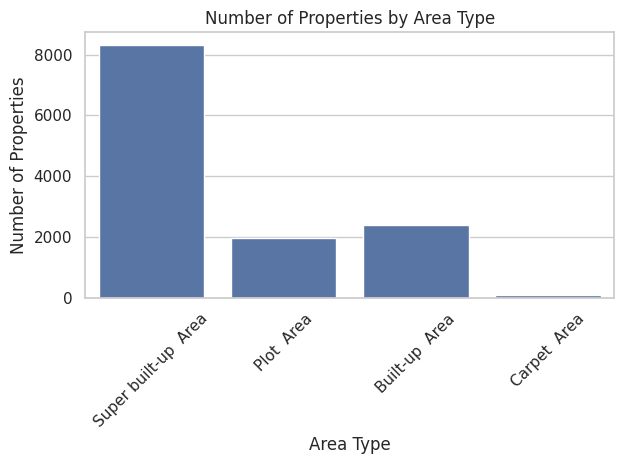

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df_clean, x="area_type")
plt.title("Number of Properties by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Number of Properties")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 2. Numerical Data Analysis

In [ ]:

df_clean[["total_sqft", "bath", "balcony", "price"]].describe()


,bath,balcony,price
count,12791.000000,12791.000000,12791.000000
mean,2.704558,1.602064,114.317646
std,1.354936,0.807728,151.480310
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,73.000000
75%,3.000000,2.000000,121.000000
max,40.000000,3.000000,3600.000000


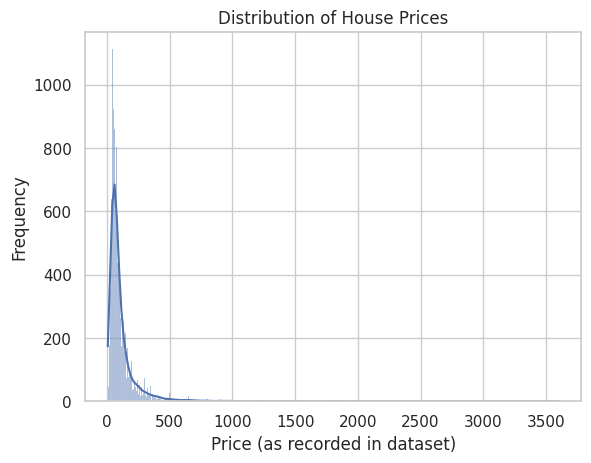

In [ ]:

sns.histplot(data=df_clean, x="price", kde=True)
plt.title("Distribution of House Prices")
plt.xlabel("Price (as recorded in dataset)")
plt.ylabel("Frequency")
plt.show()


## 3. Outlier Analysis

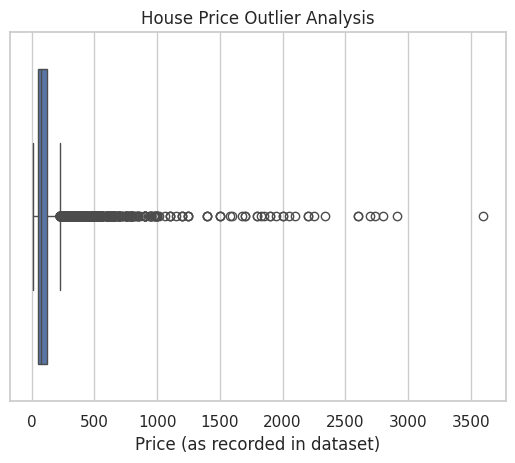

In [ ]:

sns.boxplot(data=df_clean, x="price")
plt.title("House Price Outlier Analysis")
plt.xlabel("Price (as recorded in dataset)")
plt.show()


## 4. Univariate Analysis

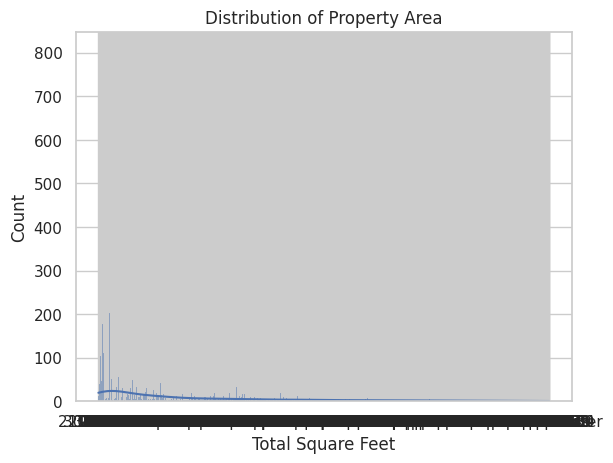

In [ ]:

sns.histplot(data=df_clean, x="total_sqft", kde=True)
plt.title("Distribution of Property Area")
plt.xlabel("Total Square Feet")
plt.show()


## 5. Bivariate Analysis

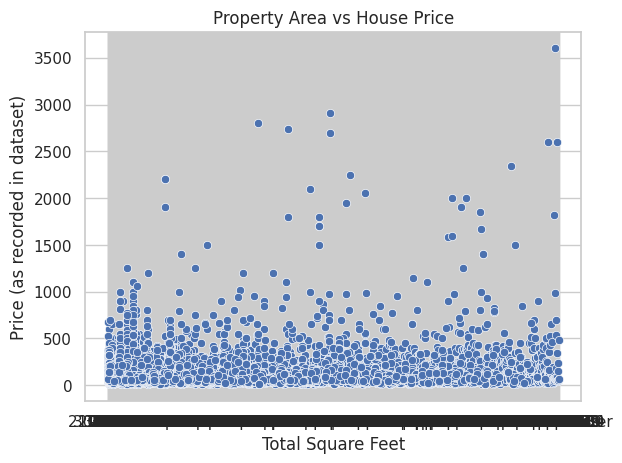

In [ ]:

sns.scatterplot(data=df_clean, x="total_sqft", y="price")
plt.title("Property Area vs House Price")
plt.xlabel("Total Square Feet")
plt.ylabel("Price (as recorded in dataset)")
plt.show()


## 6. Multivariate Analysis

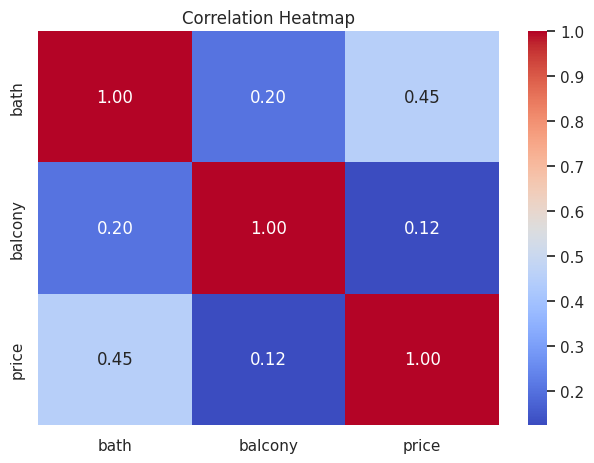

In [ ]:

numeric_df = df_clean.select_dtypes(include="number")

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


## 7. Key Insights

1. **Dataset Structure:** The Bengaluru House Price dataset initially contained 13,320 rows and 9 columns, providing information about property types, locations, sizes, bathrooms, balconies, and prices.

2. **Duplicate Records:** The initial dataset contained 529 duplicate rows. These were removed during the data-cleaning process to reduce repeated records.

3. **Missing Values:** Several columns, including `society`, `bath`, `balcony`, and `location`, contained missing values. These were handled during preprocessing, and the final missing-value check showed zero missing values in all columns.

4. **Property Size:** The `size` column contained different formats, such as bedroom counts and BHK labels. Standardizing these values makes property-size categories easier to analyze.

5. **Property Locations:** The dataset contains properties across multiple Bengaluru locations, allowing further analysis of geographical differences in house prices.

6. **Property Area:** The `total_sqft` column provides information about property size and can be compared with price to investigate whether larger properties tend to cost more.

7. **Price Distribution:** The `price` column contains different property prices. A histogram can help identify the distribution of prices and whether the data is skewed.

8. **Outlier Detection:** Boxplots can help identify unusually high or low property prices. These observations should be investigated before deciding whether they should be retained or removed.

9. **Relationships Between Variables:** Scatter plots and correlation analysis can help examine relationships between property prices, total square feet, bathrooms, and balconies.

10. **Use in Machine Learning:** After suitable preprocessing and analysis, the dataset can be used in a future machine-learning project to develop a model that predicts house prices based on property features.

## 8. Conclusion

In this project, Exploratory Data Analysis (EDA) was performed on the Bengaluru House Price dataset to understand its structure, identify data-quality issues, and prepare it for further analysis.

The data-cleaning process included checking and removing duplicate records, handling missing values, and standardizing property-size information. The final missing-value check confirmed that no null values remained in the cleaned DataFrame.

EDA techniques such as descriptive statistics, histograms, boxplots, scatter plots, and correlation heatmaps can be used to investigate property-price distributions, detect potential outliers, and understand relationships between property features.

This project demonstrates the importance of data cleaning and exploratory analysis before applying machine-learning algorithms. The cleaned dataset can serve as a foundation for a future house-price prediction model using regression techniques.

Overall, this project provided practical experience in Python, Pandas, NumPy, Matplotlib, and Seaborn, while developing an understanding of the data-analysis workflow.